# 02 – Model training and comparison (M2)

**Goal:** from a bin photo, predict for each of the 10 catalogue products how many units are in the bin (0–5).

Three approaches, all trained on **train** and compared on **validation** with the same metrics:

| | Approach | Why try it |
|---|---|---|
| A | **Majority baseline**: always predict the most common answer (0 = absent) | The floor. Any real model must beat it. |
| B | **Image-feature baseline**: frozen ImageNet ResNet-18 features + one logistic regression per product | Cheap; tests whether general-purpose image features already contain the answer. |
| C | **Fine-tuned ResNet-18**: all layers trained, one 6-way output (0–5) per product | Lets the network learn what these specific products look like. |

The **test set is not loaded here at all**. It is used once, in `03_evaluate.ipynb` (M3).

**Kaggle settings:** Accelerator = GPU (T4 or P100), Internet = On (to download the ImageNet weights),
input = the private dataset `smart-bin-data-pack`. Runtime is about 5–10 minutes.

In [1]:
import os
import json
import time
import random
from glob import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

def find_data():
    """Locate the data pack: on Kaggle under /kaggle/input, locally in data/ or ../data."""
    patterns = [f"/kaggle/input{'/*' * d}/catalogue.csv" for d in range(1, 5)] + ["data/catalogue.csv", "../data/catalogue.csv"]
    for pattern in patterns:
        hits = sorted(glob(pattern))
        if hits:
            return Path(hits[0]).parent
    raise FileNotFoundError("catalogue.csv not found: add the smart-bin-data-pack dataset as an input.")

DATA = find_data()
OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("../models")
OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PRETRAINED = os.environ.get("SBC_NO_PRETRAINED") != "1"   # only switched off for offline code tests

print("Data:", DATA, "| outputs:", OUT, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU")

Data: /kaggle/input/datasets/sreecharan1205/smart-bin-data-pack | outputs: /kaggle/working | device: cuda | Tesla T4


## 1. Load train and validation labels

In [2]:
catalogue = pd.read_csv(DATA / "catalogue.csv", dtype={"asin": str})
CAT = list(catalogue["asin"])                     # the 10 product ids, in a fixed order
NAMES = dict(zip(catalogue["asin"], catalogue["name"].str.slice(0, 40)))
K, C = len(CAT), 6                                # 10 products, counts 0..5

def load_labels(split):
    df = pd.read_csv(DATA / split / "labels.csv", dtype={"bin_id": str})
    df[CAT] = df[CAT].clip(upper=5)               # counts above 5 cannot occur (bins hold 1–5 units)
    return df

train_df, val_df = load_labels("train"), load_labels("validation")
Y_train, Y_val = train_df[CAT].to_numpy(), val_df[CAT].to_numpy()
print(f"train: {len(train_df)} bins | validation: {len(val_df)} bins | products: {K}")
print("Answer distribution in train (0..5):", np.bincount(Y_train.ravel(), minlength=C))

train: 1400 bins | validation: 200 bins | products: 10
Answer distribution in train (0..5): [12599  1054   270    55    19     3]


## 2. Metrics and the decision rule (shared by all three approaches)

Every model outputs, per product, a probability for each count 0–5. One rule turns that into an answer:
- **present** if P(count ≥ 1) is at least a threshold *t* for that product, otherwise **0**;
- if present, the count is the most likely value among 1–5.

The threshold *t* is tuned **per product on validation** to maximise F1. This matters because 90% of answers
are 0: with *t* = 0.5 a model leans towards "absent" and misses items.

Metrics (same as M3):
- **Presence:** precision, recall, F1 per product, averaged over products (macro).
- **Quantity:** exact-match accuracy and mean absolute error (MAE), on all answers and on bins where the product is present.

In [3]:
def decide(probs, thresholds):
    """probs: [n, K, 6] probabilities -> predicted counts [n, K] using the presence-threshold rule."""
    p_present = 1.0 - probs[:, :, 0]
    count_if_present = probs[:, :, 1:].argmax(axis=2) + 1
    return np.where(p_present >= np.asarray(thresholds)[None, :], count_if_present, 0)

def tune_thresholds(probs, y_true, grid=np.round(np.arange(0.05, 0.96, 0.05), 2)):
    """Pick, for each product, the threshold with the best presence F1 on the given (validation) data."""
    best = []
    for k in range(probs.shape[1]):
        p = 1.0 - probs[:, k, 0]
        truth = y_true[:, k] > 0
        f1s = []
        for t in grid:
            pred = p >= t
            tp, fp, fn = (pred & truth).sum(), (pred & ~truth).sum(), (~pred & truth).sum()
            f1s.append(2 * tp / max(2 * tp + fp + fn, 1))
        best.append(float(grid[int(np.argmax(f1s))]))
    return best

def evaluate(y_true, y_pred, names=None):
    """Presence P/R/F1 per product + quantity accuracy and MAE. Returns (summary dict, per-product table)."""
    rows = []
    for k in range(y_true.shape[1]):
        t, p = y_true[:, k] > 0, y_pred[:, k] > 0
        tp, fp, fn = int((t & p).sum()), int((~t & p).sum()), int((t & ~p).sum())
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        rows.append({"product": names[k] if names else k, "precision": prec, "recall": rec, "f1": f1, "support": int(t.sum())})
    per = pd.DataFrame(rows)
    present = y_true > 0
    summary = {
        "presence_precision": float(per["precision"].mean()),   # plain floats so the saved model file stays loadable
        "presence_recall": float(per["recall"].mean()),
        "presence_f1": float(per["f1"].mean()),
        "count_exact_all": float((y_true == y_pred).mean()),
        "count_exact_when_present": float((y_true == y_pred)[present].mean()),
        "mae_all": float(np.abs(y_true - y_pred).mean()),
        "mae_when_present": float(np.abs(y_true - y_pred)[present].mean()),
    }
    return summary, per

# Sanity check of the metric code on a tiny hand-made example
_t = np.array([[1, 0], [0, 2], [0, 0]]); _p = np.array([[1, 0], [0, 1], [1, 0]])
_s, _per = evaluate(_t, _p)
assert abs(_per.loc[0, "precision"] - 0.5) < 1e-9 and _per.loc[0, "recall"] == 1.0 and _per.loc[1, "f1"] == 1.0
assert abs(_s["mae_when_present"] - 0.5) < 1e-9
print("metric code checked")

metric code checked


## 3. Approach A – majority baseline

In [4]:
results = {}

majority = np.array([np.bincount(Y_train[:, k], minlength=C).argmax() for k in range(K)])
pred_A = np.tile(majority, (len(Y_val), 1))
results["A  majority (always the most common count)"], per_A = evaluate(Y_val, pred_A, [NAMES[a] for a in CAT])
print("Majority answer per product:", majority.tolist())
pd.DataFrame(results).T.round(3)

Majority answer per product: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


,presence_precision,presence_recall,presence_f1,count_exact_all,count_exact_when_present,mae_all,mae_when_present
A majority (always the most common count),0.0,0.0,0.0,0.9,0.0,0.14,1.405


## 4. Images → tensors

Photos are already 224×224. Training uses light augmentation (small crops, left-right flips, small colour
changes) so the model does not memorise exact photos; validation photos are only normalised.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet statistics (the pretrained weights expect these)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class BinDataset(Dataset):
    """Returns (image tensor, counts for the 10 products). Images are loaded once into memory (2,000 small JPEGs)."""
    def __init__(self, df, split, tf):
        self.images = [Image.open(DATA / split / "images" / f).convert("RGB") for f in df["image"]]
        self.y = torch.tensor(df[CAT].to_numpy(), dtype=torch.long)
        self.tf = tf
    def __len__(self):
        return len(self.images)
    def __getitem__(self, i):
        return self.tf(self.images[i]), self.y[i]

BATCH = 32
WORKERS = 2 if DEVICE == "cuda" else 0
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(BinDataset(train_df, "train", train_tf), batch_size=BATCH, shuffle=True,
                          num_workers=WORKERS, generator=g)
train_eval_loader = DataLoader(BinDataset(train_df, "train", eval_tf), batch_size=64, num_workers=WORKERS)
val_loader = DataLoader(BinDataset(val_df, "validation", eval_tf), batch_size=64, num_workers=WORKERS)
print("batches per epoch:", len(train_loader))

batches per epoch: 44


## 5. Approach B – image-feature baseline

The ImageNet ResNet-18 is used **frozen**: its last layer is removed, so every photo becomes 512 numbers
describing it. One logistic regression per product then learns counts 0–5 from those numbers.
`class_weight="balanced"` stops it from simply always answering 0.

In [6]:
def resnet18(pretrained=PRETRAINED):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    return models.resnet18(weights=weights)

@torch.no_grad()
def extract_features(loader):
    net = resnet18()
    net.fc = nn.Identity()                       # remove the ImageNet classifier: output = 512 features
    net.eval().to(DEVICE)
    return np.concatenate([net(x.to(DEVICE)).cpu().numpy() for x, _ in loader])

t0 = time.time()
F_train, F_val = extract_features(train_eval_loader), extract_features(val_loader)
print(f"features: train {F_train.shape}, validation {F_val.shape} ({time.time() - t0:.0f}s)")

def full_probs(clf, X):
    """Logistic regression only knows the counts it saw in training; place them into a 6-column array."""
    out = np.zeros((len(X), C))
    out[:, clf.classes_] = clf.predict_proba(X)
    return out

logreg = []
for k in range(K):
    clf = make_pipeline(StandardScaler(),
                        LogisticRegression(C=0.1, max_iter=3000, class_weight="balanced"))
    clf.fit(F_train, Y_train[:, k])
    logreg.append(clf)

probs_B = np.stack([full_probs(logreg[k], F_val) for k in range(K)], axis=1)
thr_B = tune_thresholds(probs_B, Y_val)
pred_B = decide(probs_B, thr_B)
results["B  frozen ResNet-18 features + logistic regression"], per_B = evaluate(Y_val, pred_B, [NAMES[a] for a in CAT])
pd.DataFrame(results).T.round(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 173MB/s] 


features: train (1400, 512), validation (200, 512) (5s)


,presence_precision,presence_recall,presence_f1,count_exact_all,count_exact_when_present,mae_all,mae_when_present
A majority (always the most common count),0.000,0.00,0.000,0.900,0.000,0.140,1.405
B frozen ResNet-18 features + logistic regression,0.685,0.69,0.674,0.916,0.525,0.108,0.635


## 6. Approach C – fine-tuned ResNet-18

The same network, but now **every layer is trained** on our photos. The ImageNet classifier is replaced by one
layer with 10 × 6 outputs: for each product, a score for each count 0–5.

- **Loss:** cross-entropy per product, with class weights (rarer counts weigh more) because 90% of answers are 0.
- **Optimiser:** AdamW; the new last layer learns 10× faster than the pretrained layers, which only need adjusting.
- **Model selection:** after every epoch the validation presence F1 is measured; the best epoch is kept, and
  training stops early if it has not improved for 6 epochs.

In [7]:
class CountNet(nn.Module):
    """ResNet-18 backbone; output [batch, products, 6] = scores for counts 0..5 per product."""
    def __init__(self, n_products, n_counts=6, pretrained=PRETRAINED):
        super().__init__()
        self.net = resnet18(pretrained)
        self.net.fc = nn.Linear(self.net.fc.in_features, n_products * n_counts)
        self.n_products, self.n_counts = n_products, n_counts
    def forward(self, x):
        return self.net(x).view(-1, self.n_products, self.n_counts)

# Class weights: 1 / sqrt(frequency), scaled to average 1; counts never seen get the largest weight
freq = np.bincount(Y_train.ravel(), minlength=C).astype(float)
w = 1.0 / np.sqrt(np.maximum(freq, 1))
w[freq == 0] = w[freq > 0].max()
w = w / w[freq > 0].mean()
print("count:  ", list(range(C)))
print("weight: ", np.round(w, 2).tolist())

@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    return np.concatenate([torch.softmax(model(x.to(DEVICE)), dim=2).cpu().numpy() for x, _ in loader])

def train_model(epochs=25, patience=6, lr=1e-4):
    torch.manual_seed(SEED)
    model = CountNet(K).to(DEVICE)
    head = list(model.net.fc.parameters())
    body = [p for n, p in model.net.named_parameters() if not n.startswith("fc.")]
    opt = torch.optim.AdamW([{"params": body, "lr": lr}, {"params": head, "lr": lr * 10}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))

    history, best_f1, best_state, waited = [], -1.0, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        t0, total = time.time(), 0.0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = loss_fn(model(x).reshape(-1, C), y.reshape(-1))
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(x)
        sched.step()

        probs = predict_probs(model, val_loader)
        val_loss = float(-np.log(np.take_along_axis(probs, Y_val[..., None], axis=2) + 1e-9).mean())
        f1 = evaluate(Y_val, decide(probs, [0.5] * K))[0]["presence_f1"]
        history.append({"epoch": epoch, "train_loss": total / len(train_loader.dataset), "val_loss": val_loss, "val_f1@0.5": f1})
        print(f"epoch {epoch:2d}  train loss {history[-1]['train_loss']:.3f}  val loss {val_loss:.3f}  "
              f"val F1 {f1:.3f}  ({time.time() - t0:.0f}s)")
        if f1 > best_f1:
            best_f1, waited = f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                print(f"no improvement for {patience} epochs: stopping")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

EPOCHS = int(os.environ.get("SBC_EPOCHS", 25))
model, history = train_model(epochs=EPOCHS)

count:   [0, 1, 2, 3, 4, 5]
weight:  [0.05, 0.18, 0.35, 0.78, 1.32, 3.32]
epoch  1  train loss 1.021  val loss 0.438  val F1 0.544  (6s)
epoch  2  train loss 0.586  val loss 0.316  val F1 0.653  (5s)
epoch  3  train loss 0.404  val loss 0.240  val F1 0.713  (5s)
epoch  4  train loss 0.275  val loss 0.224  val F1 0.763  (5s)
epoch  5  train loss 0.202  val loss 0.219  val F1 0.768  (5s)
epoch  6  train loss 0.145  val loss 0.204  val F1 0.775  (5s)
epoch  7  train loss 0.095  val loss 0.196  val F1 0.789  (5s)
epoch  8  train loss 0.072  val loss 0.193  val F1 0.773  (5s)
epoch  9  train loss 0.053  val loss 0.185  val F1 0.790  (5s)
epoch 10  train loss 0.042  val loss 0.188  val F1 0.794  (5s)
epoch 11  train loss 0.036  val loss 0.187  val F1 0.779  (5s)
epoch 12  train loss 0.030  val loss 0.191  val F1 0.789  (6s)
epoch 13  train loss 0.021  val loss 0.186  val F1 0.803  (6s)
epoch 14  train loss 0.020  val loss 0.190  val F1 0.799  (6s)
epoch 15  train loss 0.016  val loss 0.191  

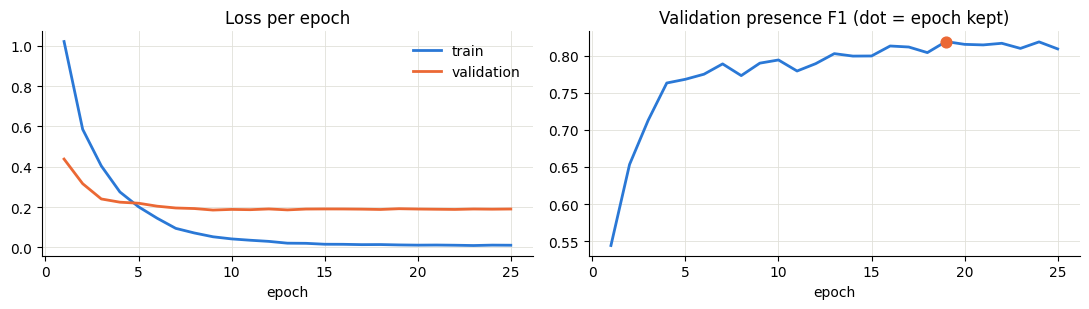

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(history["epoch"], history["train_loss"], color="#2a78d6", lw=2, label="train")
axes[0].plot(history["epoch"], history["val_loss"], color="#eb6834", lw=2, label="validation")
axes[0].set_title("Loss per epoch"); axes[0].set_xlabel("epoch"); axes[0].legend(frameon=False)
axes[1].plot(history["epoch"], history["val_f1@0.5"], color="#2a78d6", lw=2)
best = history["val_f1@0.5"].idxmax()
axes[1].scatter(history.loc[best, "epoch"], history.loc[best, "val_f1@0.5"], color="#eb6834", s=60, zorder=3)
axes[1].set_title("Validation presence F1 (dot = epoch kept)"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e1e0d9", lw=0.6)
plt.tight_layout(); plt.savefig(OUT / "training_curves.png", dpi=120); plt.show()

In [9]:
probs_C = predict_probs(model, val_loader)
thr_C = tune_thresholds(probs_C, Y_val)
pred_C = decide(probs_C, thr_C)
results["C  fine-tuned ResNet-18"], per_C = evaluate(Y_val, pred_C, [NAMES[a] for a in CAT])

## 7. Comparison on validation

,presence_precision,presence_recall,presence_f1,count_exact_all,count_exact_when_present,mae_all,mae_when_present
A majority (always the most common count),0.000,0.00,0.000,0.900,0.000,0.140,1.405
B frozen ResNet-18 features + logistic regression,0.685,0.69,0.674,0.916,0.525,0.108,0.635
C fine-tuned ResNet-18,0.904,0.80,0.840,0.954,0.645,0.059,0.445


,product,support,F1 baseline B,F1 fine-tuned C,threshold C
0,TaoTronics TT-AH002 30W Ultrasonic Humid,20,0.86,0.93,0.45
1,Fujifilm Instax Mini Instant Film (3 Twi,20,0.58,0.89,0.15
2,RTIC 30 oz. Tumbler,20,0.45,0.80,0.35
3,Pumpkin Pie Quest Bars 2 Pack Total of 2,20,0.65,0.92,0.60
4,Laser Lights Outdoor Starry Projector Re,20,0.63,0.75,0.95
5,"Best Microfiber Cleaning Cloth, Pack of",20,0.95,0.95,0.15
6,Lifetime Warranty FDA cleared OTC Health,20,0.71,0.78,0.30
7,3M 8511 Particulate N95 Respirator with,20,0.71,0.83,0.95
8,"UP2 by Jawbone Activity + Sleep Tracker,",20,0.59,0.86,0.50
9,"AuYou Wi-Fi Smart Outlet Switch, 5 Outle",20,0.62,0.68,0.20


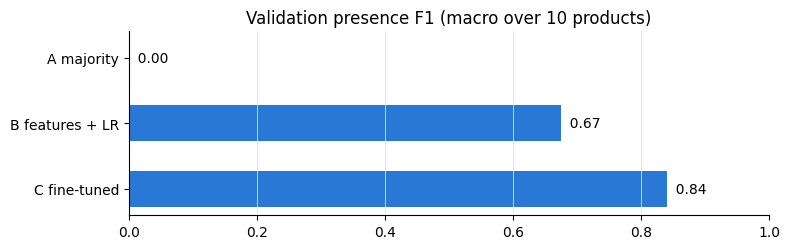

In [10]:
comparison = pd.DataFrame(results).T
display(comparison.round(3))

per_product = pd.DataFrame({"product": per_C["product"], "support": per_C["support"],
                            "F1 baseline B": per_B["f1"].round(2), "F1 fine-tuned C": per_C["f1"].round(2),
                            "threshold C": thr_C})
display(per_product)

fig, ax = plt.subplots(figsize=(8, 2.6))
names = ["A majority", "B features + LR", "C fine-tuned"]
bars = ax.barh(names[::-1], comparison["presence_f1"].to_numpy()[::-1], color="#2a78d6", height=0.55)
for b in bars:
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {b.get_width():.2f}", va="center")
ax.set_xlim(0, 1); ax.set_title("Validation presence F1 (macro over 10 products)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e1e0d9", lw=0.6)
plt.tight_layout(); plt.savefig(OUT / "validation_comparison.png", dpi=120); plt.show()

**Caution about these numbers:** the thresholds were tuned on this same validation set and the best epoch was
picked on it, so validation scores are slightly optimistic. The honest numbers come from the untouched test
set in `03_evaluate.ipynb`.

**Final choice (write your own reason after reading the table):** the model with the best validation presence
F1 is the one used by the app, unless its quantity errors are clearly worse. Note what each approach gets
wrong, not only the scores.

## 8. Save the models

In [11]:
# Fine-tuned model: weights stored as 16-bit floats to halve the file size (~22 MB); loaded back as 32-bit
torch.save({
    "arch": "resnet18",
    "state_dict": {k: (v.half() if v.is_floating_point() else v) for k, v in model.state_dict().items()},
    "catalogue": CAT,
    "thresholds": thr_C,
    "mean": MEAN, "std": STD, "image_size": 224, "n_counts": C,
    "val_metrics": results["C  fine-tuned ResNet-18"],
}, OUT / "smartbin_resnet18.pt")

joblib.dump({"models": logreg, "thresholds": thr_B, "catalogue": CAT}, OUT / "baseline_logreg.joblib")
json.dump({"majority": majority.tolist(), "catalogue": CAT}, open(OUT / "baseline_majority.json", "w"))
history.to_csv(OUT / "training_history.csv", index=False)
comparison.to_csv(OUT / "validation_comparison.csv")

for f in sorted(OUT.glob("*")):
    if f.is_file():
        print(f"{f.name:32s} {f.stat().st_size / 1e6:6.1f} MB")

baseline_logreg.joblib              0.3 MB
baseline_majority.json              0.0 MB
smartbin_resnet18.pt               22.5 MB
training_curves.png                 0.0 MB
training_history.csv                0.0 MB
validation_comparison.csv           0.0 MB
validation_comparison.png           0.0 MB


In [12]:
# Check the saved file loads back and gives the same answers
ckpt = torch.load(OUT / "smartbin_resnet18.pt", map_location="cpu")
reloaded = CountNet(len(ckpt["catalogue"]), pretrained=False)
reloaded.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ckpt["state_dict"].items()})
reloaded.to(DEVICE)
same = (decide(predict_probs(reloaded, val_loader), ckpt["thresholds"]) == pred_C).mean()
print(f"reloaded model agrees with the trained one on {same:.1%} of validation answers")

reloaded model agrees with the trained one on 100.0% of validation answers


In [13]:
   # Zip all training outputs into one file for download
   import shutil
   from IPython.display import FileLink
   shutil.make_archive("/tmp/model_outputs", "zip", "/kaggle/working")
   shutil.move("/tmp/model_outputs.zip", "/kaggle/working/model_outputs.zip")
   FileLink("model_outputs.zip")


/kaggle/working/model_outputs.zip